# La PINN como baseline (L0)

**Equipo 39 · Proyecto Integrador MNA · Avance 3**

Esta sección presenta el primero de nuestros modelos de referencia: una red neuronal informada por la física (PINN) que estima el módulo de Young de una viga a partir de su forma de vibración, tratando la física de la viga ideal como exacta. Explica por qué el algoritmo es apropiado, cómo se fijó su configuración y si sub o sobreajusta. Se ejecuta completa de principio a fin (*Run All*) desde el repositorio en menos de un minuto: lee las 220 corridas ya guardadas y entrena en vivo solo dos redes pequeñas.

**En tres frases:**
1. La PINN recupera el módulo de Young con un error mediano de 0.02 % o menos cuando el anclaje de la viga es perfecto, y con una dispersión entre semillas menor a 0.1 % en todos los casos.
2. No sobreajusta: el error en puntos que la red no vio es igual al error en los puntos de entrenamiento y está al nivel del ruido de medición, y agregar puntos casi no cambia el resultado.
3. Cuando el anclaje cede, la red ajusta la forma igual de bien pero el módulo de Young sale sesgado (hasta −15 %): ese error de modelo no se ve dentro de la muestra y solo aparece al predecir vigas de otras longitudes, lo que motiva los modelos de las siguientes etapas.

### Términos

| Término | Significado |
|---|---|
| **Módulo de Young, E** | Qué tan rígido es el material. Es la variable objetivo: lo que queremos estimar |
| **Voladizo / biempotrada** | Viga sujeta de un extremo (como un trampolín) / de los dos (como un puente) |
| **Forma modal** | La forma que toma la viga al vibrar en uno de sus modos. Se mide en N puntos a lo largo de la viga; su amplitud es arbitraria |
| **Frecuencia, ω** | Qué tan rápido vibra la viga en cada modo. Se mide junto con la forma |
| **Esfuerzo residual, σ₀** | Tensión o compresión que queda en la viga al fabricarla. Solo cambia las frecuencias de la biempotrada |
| **Anclaje** | Dónde la viga se une al chip. Un anclaje perfecto no cede; uno real gira un poco y hace que la viga vibre más lento |
| **PINN** | Red neuronal informada por la física: se entrena para pasar por los puntos medidos y, a la vez, cumplir la ecuación de la viga. E es un número que la red aprende junto con sus pesos |
| **λ_PDE** | Cuánto pesa la ecuación de la viga en el entrenamiento, comparada con los datos |
| **L-BFGS** | Optimizador de segundo orden que afina el entrenamiento después del optimizador Adam |
| **L0** | El primer escalón de modelos: supone que la física ideal (anclaje perfecto) es exacta. Los escalones L1–L3 relajan o enriquecen esa física |
| **M0 / M1** | Datos sintéticos de una viga con anclaje perfecto (M0) o con un anclaje que cede al giro (M1) |
| **s1, s3, s5** | Severidad del anclaje en M1. Con la fórmula estándar, cada una produce un sesgo conocido en E: −1 %, −5 % y −15 % |
| **k** | Número de estructuras medidas: k = 1 es un voladizo de 300 µm; k = 3 agrega una biempotrada de 300 µm y un voladizo de 200 µm con el mismo anclaje |
| **Semilla** | Número que fija el ruido de medición y la inicialización de la red. Cada caso se corre con 10 semillas |
| **Sesgo / dispersión** | Mediana del error relativo sobre las 10 semillas / su rango intercuartílico (IQR) |
| **χ² reducido** | Error cuadrático de ajuste dividido entre la varianza del ruido. Cerca de 1: ajuste correcto; mucho menor: sobreajuste; mucho mayor: subajuste |

### Contenido

1. [El algoritmo y por qué es apropiado](#1.-El-algoritmo-y-por-qué-es-apropiado)
2. [Cómo se fijó la configuración](#2.-Cómo-se-fijó-la-configuración)
3. [Una corrida de ejemplo](#3.-Una-corrida-de-ejemplo)
4. [¿Sub o sobreajuste?](#4.-¿Sub-o-sobreajuste?)
5. [Resultados en todas las celdas](#5.-Resultados-en-todas-las-celdas)
6. [Conclusión](#6.-Conclusión)

### Preparación

Esta celda localiza el código del proyecto (`src/pinn_mems`), carga las librerías y lee los resultados guardados de la PINN. Requiere `numpy`, `scipy`, `pyyaml`, `pandas`, `matplotlib` y `torch`.

In [1]:
import sys
from dataclasses import asdict, replace
from pathlib import Path

# Busca la raíz del repositorio subiendo desde la carpeta actual
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pinn_mems").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pinn_mems import Viga, resolver_modos
from pinn_mems.almacen import ALMACEN, leer
from pinn_mems.matriz import Corrida, frecuencias_reservadas, generar_corrida
from pinn_mems.pinn import entrenar
from pinn_mems.pinn.arnes import CONFIG_L0, hash_metodo, mediciones_de_corrida

pd.set_option("display.float_format", lambda v: f"{v:.3g}")
COLOR = "#2a6f97"  # color de la PINN en todas las figuras del Avance 3
RUIDO = 0.02  # desviación estándar del ruido de forma, relativa a la amplitud pico

# Resultados de las 220 corridas: un archivo por corrida, en la carpeta de la config L0
carpeta = ALMACEN / "pinn_l0" / hash_metodo(CONFIG_L0)
filas = []
for archivo in sorted(carpeta.glob("*.json")):
    r = leer(archivo)
    c = Corrida.desde_id(r.extra["corrida"])
    fila = r.a_fila(r.extra["verdaderos"])
    filas.append({"caso": c.caso, "N": c.N, "k": c.k, "modos": r.extra["n_modos"], "sin_ruido": r.extra["sin_ruido"],
                  "semilla": c.semilla, "error_E_pct": 100 * fila["err_E"],
                  "error_sigma0_pct": 100 * fila.get("err_sigma0", np.nan), "fallo": fila["fallo"],
                  "chi2_reducido": r.residuales["datos"] / RUIDO**2, "tiempo_s": r.tiempo_s})
corridas = pd.DataFrame(filas)
print(f"{len(corridas)} corridas leídas de {carpeta.relative_to(RAIZ)}; fallas: {corridas['fallo'].sum()}")

220 corridas leídas de resultados/avance3/pinn_l0/767d18e8e49a; fallas: 0


## 1. El algoritmo y por qué es apropiado

**El problema.** Queremos estimar el módulo de Young E de una viga microscópica a partir de mediciones de su vibración: la forma modal en 5 a 40 puntos y la frecuencia de 1 a 3 modos, en una a tres estructuras. Es un problema de regresión de un parámetro físico con **pocos datos estructurados** (decenas de números por caso, no miles de ejemplos etiquetados) y con **física conocida**: la ecuación de la viga.

**Por qué una PINN y no otro algoritmo de aprendizaje automático:**

| Opción | Qué necesitaría | Por qué no, o por qué sí |
|---|---|---|
| Red neuronal supervisada (de mediciones a E) | Miles de vigas con E conocido para aprender la relación | No existen esos datos reales; con datos sintéticos aprendería el simulador, sin garantía fuera de él |
| Regresión lineal o árboles sobre características | Una relación aproximadamente fija entre características y E | La relación es no lineal ($\omega^2 \propto E$) y depende de la geometría; las características útiles ya son la física |
| **PINN** | Los puntos medidos de una sola viga y la ecuación | La ecuación entra en la pérdida y suple la falta de datos. **E es un número que la red entrena junto con sus pesos**, así que el resultado es directamente interpretable |

**Cómo funciona.** Cada modo medido tiene una red pequeña que recibe la posición a lo largo de la viga y devuelve la forma y el momento flector. El entrenamiento minimiza la suma de dos cosas: que la forma pase por los puntos medidos y que se cumpla la ecuación de la viga en 128 puntos internos. La frecuencia medida entra como dato, así que la única incógnita física es E (y σ₀ cuando hay biempotrada).

**Qué significa L0.** La ecuación supone un anclaje perfecto y se trata como exacta. Es el modelo de referencia más simple con física: si el anclaje real cede, el modelo no tiene cómo representarlo y el error se va a E. Medir cuánto, y compararlo con la fórmula estándar y con el ajuste clásico, es el propósito del baseline.

**Lo que no afirmamos.** En una viga de una dimensión con dos incógnitas, el ajuste clásico por mínimos cuadrados es más barato (segundos contra minutos). La PINN se justifica porque en los siguientes escalones puede relajar la física o agregarle términos de discrepancia sin cambiar de método.

La configuración de la red:

In [2]:
config = {k: v for k, v in asdict(CONFIG_L0).items() if k not in ("semilla", "invertir_n", "registrar_cada", "hilos")}
pd.Series({k: str(v) for k, v in config.items()}, name="valor").to_frame()

,valor
capas,"(32, 32, 32)"
cf,duras
pesos,"{'datos': 1.0, 'r1': 1.0, 'r2': 1.0, 'cf': 1.0}"
n_colocacion,128
iter_adam,3000
lr,0.001
iter_lbfgs,2000
invertir_E,True
theta0,0.8
tol_convergencia,0.01


## 2. Cómo se fijó la configuración

Dos valores se eligieron con experimentos y no por costumbre: el peso de la física (λ_PDE) y el número de iteraciones de L-BFGS. Se probaron en M0 con 15 puntos y 3 semillas, en la celda más barata (k = 1, 1 modo) y en la más cara (k = 3, 3 modos).

**El peso de la física.** En L0 la física debe cumplirse prácticamente exacta, así que se buscaba un λ_PDE "alto". La tabla muestra el error máximo en E y en σ₀, la fracción de corridas que convergieron y la mediana de la pérdida de datos y del residual de la ecuación (con 500 iteraciones de L-BFGS):

In [3]:
lam = pd.read_csv(RAIZ / "resultados" / "lambda-pde" / "resumen.csv")
lam[["lambda_pde", "k", "modos", "max_abs_error_E_pct", "max_abs_error_sigma0_pct", "convergio", "perdida_datos", "perdida_r2"]]

,lambda_pde,k,modos,max_abs_error_E_pct,max_abs_error_sigma0_pct,convergio,perdida_datos,perdida_r2
0,1,1,1,0.073,NaN,1,0.000244,3.36e-08
1,1,3,3,0.106,1.78,1,0.000289,2.14e-05
2,10,1,1,0.0756,NaN,1,0.000244,1.25e-08
3,10,3,3,0.246,3.45,1,0.000324,1.73e-05
4,100,1,1,0.0748,NaN,1,0.000244,3.49e-09
5,100,3,3,1.18,16.7,0,0.0165,8.87e-05


- Con λ_PDE = 1 el residual de la ecuación ya es unas 7 000 veces menor que la pérdida de datos con k = 1: la física se cumple prácticamente exacta. Esto es posible porque las ecuaciones están adimensionalizadas y todos los términos tienen escala cercana a 1.
- λ_PDE = 10 no mejora el error en E y hace σ₀ más variable entre semillas.
- Con λ_PDE = 100 el entrenamiento se rompe en k = 3: la red ya no logra ajustar los datos (su pérdida queda unas 60 veces arriba del nivel del ruido) y σ₀ sale con hasta 17 % de error.

Se fijó **λ_PDE = 1**.

**Las iteraciones de L-BFGS.** Sin ruido y con k = 3 y 3 modos, σ₀ salía con −2 % a −3 % de error, y el residual de la ecuación era el término más grande de la pérdida: el optimizador se detenía antes de converger. Con 2000 iteraciones en lugar de 500:

In [4]:
lbfgs = pd.concat([
    pd.read_csv(RAIZ / "resultados" / "lambda-pde" / f"resumen{sufijo}.csv").query("lambda_pde == 1").assign(datos=datos, iter_lbfgs=n)
    for sufijo, datos, n in [("", "con ruido", 500), ("_lbfgs2000", "con ruido", 2000),
                             ("_sin_ruido", "sin ruido", 500), ("_sin_ruido_lbfgs2000", "sin ruido", 2000)]
])
lbfgs.query("k == 3")[["datos", "iter_lbfgs", "max_abs_error_E_pct", "max_abs_error_sigma0_pct", "perdida_datos", "perdida_r2"]]

,datos,iter_lbfgs,max_abs_error_E_pct,max_abs_error_sigma0_pct,perdida_datos,perdida_r2
1,con ruido,500,0.106,1.78,0.000289,2.14e-05
1,con ruido,2000,0.0668,0.509,0.000289,7.37e-06
0,sin ruido,500,0.236,3,9.8e-08,1.48e-05
1,sin ruido,2000,0.0183,0.185,1.87e-09,3.86e-07


Con 2000 iteraciones el error en σ₀ sin ruido baja de 3 % a 0.2 %, y con ruido la pérdida de datos se queda en el mismo nivel que con 500: las iteraciones extra terminan de cumplir la ecuación, no ajustan el ruido. El costo sube unos 35 % solo en la celda más cara, porque en las demás el optimizador se detiene solo al converger. Se fijaron **2000 iteraciones de L-BFGS**.

## 3. Una corrida de ejemplo

Entrenamos en vivo una PINN sobre un voladizo M0 con 15 puntos medidos y ruido. Para poder medir el sobreajuste, **apartamos 5 de los 15 puntos** como conjunto de prueba: la red se entrena con los otros 10. Tarda unos 30 segundos.

In [5]:
PRUEBA = np.arange(1, 15, 3)  # 5 puntos repartidos a lo largo de la viga
ENTRENAMIENTO = np.setdiff1d(np.arange(15), PRUEBA)


def entrenar_con_retenidos(caso):
    """Entrena con 10 de los 15 puntos y devuelve el resultado, la medición completa y la forma sin ruido."""
    conjuntos = generar_corrida(Corrida(caso, N=15, k=1, semilla=0))
    medicion = mediciones_de_corrida(conjuntos, 1)[0]
    parcial = replace(medicion, xi=medicion.xi[ENTRENAMIENTO], W=medicion.W[ENTRENAMIENTO])
    resultado = entrenar([parcial], replace(CONFIG_L0, semilla=0))
    return resultado, medicion, conjuntos["voladizo"].w_limpia[0]


ejemplo, medicion, limpia = entrenar_con_retenidos("m0")
print(f"E estimado: {ejemplo.parametros['E'] / 1e9:.3f} GPa (verdadero 70 GPa; error {100 * (ejemplo.parametros['E'] / 70e9 - 1):+.3f} %)")
print(f"Tiempo: {ejemplo.tiempo_s:.0f} s; convergió: {ejemplo.convergio}")

E estimado: 69.984 GPa (verdadero 70 GPa; error -0.023 %)
Tiempo: 22 s; convergió: True


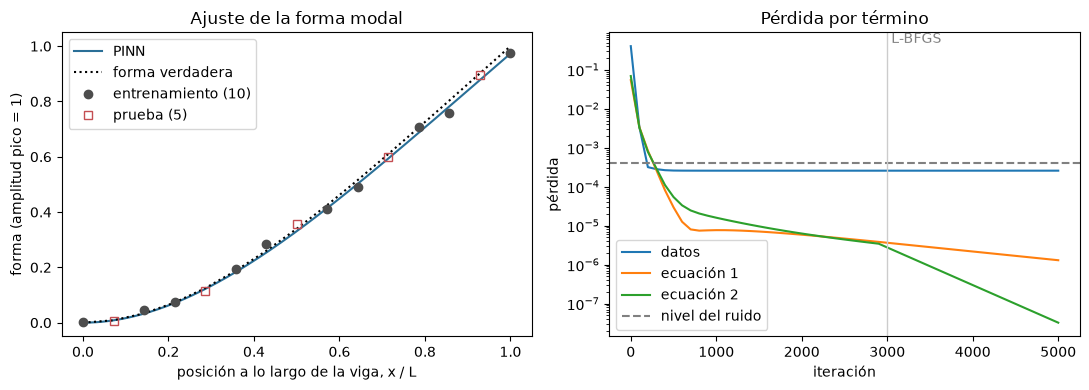

In [6]:
xi = np.linspace(0, 1, 200)
W, _ = ejemplo.extra["predecir"](0, xi)
historial = pd.DataFrame(ejemplo.extra["historial"])

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.plot(xi, W, color=COLOR, label="PINN")
a.plot(medicion.xi, limpia, "k:", label="forma verdadera")
a.plot(medicion.xi[ENTRENAMIENTO], medicion.W[ENTRENAMIENTO], "o", color="0.3", label="entrenamiento (10)")
a.plot(medicion.xi[PRUEBA], medicion.W[PRUEBA], "s", mfc="none", color="#c44e52", label="prueba (5)")
a.set(xlabel="posición a lo largo de la viga, x / L", ylabel="forma (amplitud pico = 1)", title="Ajuste de la forma modal")
a.legend()
for termino, nombre in [("datos", "datos"), ("r1", "ecuación 1"), ("r2", "ecuación 2")]:
    b.semilogy(historial["iter"], historial[termino], label=nombre)
b.axhline(RUIDO**2, color="0.5", ls="--", label="nivel del ruido")
b.axvline(CONFIG_L0.iter_adam, color="0.8", lw=1)
b.text(CONFIG_L0.iter_adam, b.get_ylim()[1], " L-BFGS", va="top", color="0.5")
b.set(xlabel="iteración", ylabel="pérdida", title="Pérdida por término")
b.legend()
plt.tight_layout()
plt.show()

La red pasa por los puntos de entrenamiento y también cerca de los de prueba, que no vio. En la derecha, la pérdida de datos baja hasta el nivel del ruido y ahí se queda, mientras los residuales de la ecuación siguen bajando hasta valores mucho menores: la red cumple la física y no persigue el ruido.

## 4. ¿Sub o sobreajuste?

Revisamos tres señales: el error en puntos que la red no vio, cómo cambia el resultado con más puntos y si el modelo predice bien vigas que no se usaron para ajustar.

### 4.1 Entrenamiento contra prueba

Repetimos la corrida de ejemplo con un anclaje que cede (M1, severidad s3) y comparamos, en ambos casos, el error cuadrático medio (RMSE) de la forma en los puntos de entrenamiento y en los de prueba, contra el nivel del ruido:

In [7]:
def rmse(a):
    return float(np.sqrt(np.mean(np.square(a))))


filas = []
for caso, (r, m, w_limpia) in [("M0", (ejemplo, medicion, limpia)), ("M1 s3", entrenar_con_retenidos("m1_s3"))]:
    W, _ = r.extra["predecir"](0, m.xi)
    filas.append({"caso": caso, "error en E (%)": 100 * (r.parametros["E"] / 70e9 - 1),
                  "RMSE entrenamiento": rmse(W[ENTRENAMIENTO] - m.W[ENTRENAMIENTO]),
                  "RMSE prueba": rmse(W[PRUEBA] - m.W[PRUEBA]), "nivel del ruido": rmse(m.W - w_limpia)})
pd.DataFrame(filas).set_index("caso")

,error en E (%),RMSE entrenamiento,RMSE prueba,nivel del ruido
caso,,,,
M0,-0.0231,0.0161,0.0157,0.0186
M1 s3,-5.02,0.0186,0.0167,0.0186


- **En M0** los errores de entrenamiento y de prueba son iguales y están al nivel del ruido. Un modelo sobreajustado tendría error de entrenamiento menor que el ruido y error de prueba mayor; uno subajustado, los dos muy por encima del ruido. No pasa ninguna de las dos cosas.
- **En M1 s3** la forma también se ajusta al nivel del ruido, en entrenamiento y en prueba, **aunque E sale con −5 % de error**. El anclaje que cede cambia la forma muy poco y la frecuencia mucho; el modelo L0 compensa la frecuencia con un E menor y la forma sigue cuadrando. Las métricas dentro de la muestra no delatan este error de modelo.

### 4.2 Curva de aprendizaje

Con las corridas guardadas (M0 con ruido, k = 1, 1 modo, 10 semillas por punto) vemos cómo cambian el error en E y el χ² reducido al pasar de 5 a 15 y a 40 puntos medidos:

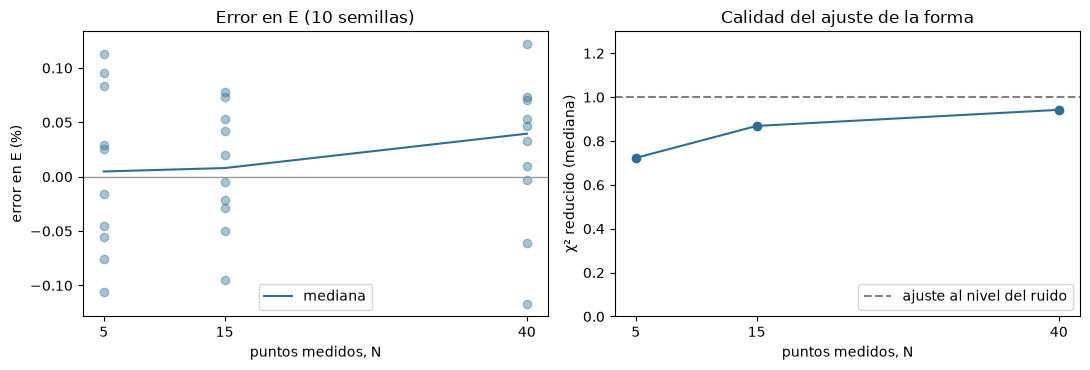

,sesgo_E_pct,iqr_E_pct,max_abs_E_pct,chi2_reducido
N,,,,
5,0.0048,0.123,0.113,0.723
15,0.00796,0.0777,0.0954,0.869
40,0.0396,0.0659,0.122,0.942


In [8]:
curva = corridas.query("caso == 'm0' and k == 1 and modos == 1 and not sin_ruido")
resumen_curva = curva.groupby("N").agg(
    sesgo_E_pct=("error_E_pct", "median"),
    iqr_E_pct=("error_E_pct", lambda x: x.quantile(0.75) - x.quantile(0.25)),
    max_abs_E_pct=("error_E_pct", lambda x: x.abs().max()),
    chi2_reducido=("chi2_reducido", "median"),
)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
for N, g in curva.groupby("N"):
    a.plot(np.full(len(g), N), g["error_E_pct"], "o", color=COLOR, alpha=0.4)
a.plot(resumen_curva.index, resumen_curva["sesgo_E_pct"], "-", color=COLOR, label="mediana")
a.axhline(0, color="0.6", lw=1)
a.set(xticks=[5, 15, 40], xlabel="puntos medidos, N",
      ylabel="error en E (%)", title="Error en E (10 semillas)")
a.legend()
b.plot(resumen_curva.index, resumen_curva["chi2_reducido"], "o-", color=COLOR)
b.axhline(1, color="0.5", ls="--", label="ajuste al nivel del ruido")
b.set(xticks=[5, 15, 40], ylim=(0, 1.3), xlabel="puntos medidos, N",
      ylabel="χ² reducido (mediana)", title="Calidad del ajuste de la forma")
b.legend(loc="lower right")
plt.tight_layout()
plt.show()
resumen_curva

- **El error en E casi no depende de N:** con 5, 15 o 40 puntos se queda por debajo de 0.13 % en las 10 semillas. La frecuencia medida fija E; la forma solo confirma que la viga es la que el modelo supone. No hay subajuste.
- **El χ² reducido sube hacia 1 al crecer N** (0.72, 0.87 y 0.94). Con pocos puntos la red absorbe una parte pequeña del ruido, el equivalente a 1 o 2 parámetros libres, que es un sobreajuste leve de la forma. Al crecer N desaparece, y en ningún caso se traslada a E.

### 4.3 Prueba fuera de muestra: vigas de otras longitudes

El chip del NIST tiene voladizos de 248 µm y 348 µm que no se usan para ajustar. Con el E que estimó la PINN en el voladizo de 300 µm (mediana de 10 semillas, 1 modo) predecimos con el modelo L0 la frecuencia fundamental de esas dos vigas y la comparamos con la verdadera:

In [9]:
reservadas = pd.DataFrame(frecuencias_reservadas())
filas = []
for caso in ["m0", "m1_s1", "m1_s3", "m1_s5"]:
    E = corridas.query("caso == @caso and k == 1 and modos == 1 and N == 15 and not sin_ruido")["error_E_pct"].median()
    E = 70e9 * (1 + E / 100)
    for L in (248.0, 348.0):
        viga = Viga(E=E, L=L * 1e-6, b=28e-6, h=2.743e-6, rho=2200.0)
        prediccion = resolver_modos(viga, "voladizo", n_modos=1).omega[0]
        verdadera = reservadas.query("caso == @caso and L_um == @L")["omega1_rad_s"].item()
        filas.append({"caso": caso, "L (µm)": L, "error en E (%)": 100 * (E / 70e9 - 1),
                      "error en la frecuencia predicha (%)": 100 * (prediccion / verdadera - 1)})
fuera = pd.DataFrame(filas)
fuera.pivot(index="caso", columns="L (µm)", values="error en la frecuencia predicha (%)").join(
    fuera.groupby("caso")["error en E (%)"].first())

,248,348,error en E (%)
caso,,,
m0,0.00398,0.00398,0.00796
m1_s1,0.108,-0.0655,-0.993
m1_s3,0.528,-0.341,-4.99
m1_s5,1.57,-1.04,-15


- **En M0** la predicción es exacta (0.004 %): el modelo generaliza a otras longitudes.
- **En M1 el error crece con la severidad y cambia de signo con la longitud:** la frecuencia de la viga corta se sobreestima y la de la larga se subestima. Un anclaje que cede pesa más en una viga corta, y un solo E no puede compensarlo en todas las longitudes a la vez.

Esta es la señal de **subajuste por error de modelo**: el modelo L0 es demasiado simple para la viga real. No se ve en el ajuste de la forma ni en la curva de aprendizaje, solo al predecir fuera de la muestra. Es la misma firma que el NIST observa en sus mediciones (el módulo de Young aparente cambia con la longitud de la viga).

## 5. Resultados en todas las celdas

Error relativo en E y en σ₀ en todas las celdas con ruido y N = 15 (10 semillas cada una). "Sesgo" es la mediana y "dispersión" el rango intercuartílico:

In [10]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)


principal = corridas.query("N == 15 and not sin_ruido")
tabla = principal.groupby(["caso", "k", "modos"]).agg(
    sesgo_E_pct=("error_E_pct", "median"), dispersion_E_pct=("error_E_pct", iqr),
    sesgo_sigma0_pct=("error_sigma0_pct", "median"), fallas=("fallo", "sum"), tiempo_s=("tiempo_s", "median"))
verificacion = corridas.query("sin_ruido").groupby(["k", "modos"]).agg(
    max_abs_E_pct=("error_E_pct", lambda x: x.abs().max()),
    max_abs_sigma0_pct=("error_sigma0_pct", lambda x: x.abs().max()), fallas=("fallo", "sum"))
print("M0 sin ruido (verificación):")
display(verificacion)
print("Con ruido:")
tabla

M0 sin ruido (verificación):


max_abs_E_pct  max_abs_sigma0_pct  fallas
k modos                                           
1 1            0.00929                 NaN       0
  3            0.00324                 NaN       0
3 1            0.00419              0.0405       0
  3              0.052               0.673       0

Con ruido:


sesgo_E_pct  dispersion_E_pct  sesgo_sigma0_pct  fallas  \
caso  k modos                                                            
m0    1 1          0.00796            0.0777               NaN       0   
        3           0.0182            0.0678               NaN       0   
      3 1          -0.0239            0.0714            -0.137       0   
        3            0.022            0.0836             0.206       0   
m1_s1 1 1           -0.993            0.0748               NaN       0   
        3           -0.974            0.0664               NaN       0   
      3 1            -1.28            0.0675              1.64       0   
        3            -1.37            0.0458              1.71       0   
m1_s3 1 1            -4.99            0.0816               NaN       0   
        3            -4.79            0.0617               NaN       0   
      3 1            -6.25            0.0446              7.45       0   
        3            -6.43            0.0734              8.94       0   
m1_s5 1 1              -15            0.0627               NaN       0   
        3            -13.4            0.0519               NaN       0   
      3 1            -18.2            0.0778              14.4       0   
        3            -16.7            0.0366              22.9       0   

               tiempo_s  
caso  k modos            
m0    1 1          27.4  
        3          81.5  
      3 1          83.8  
        3           229  
m1_s1 1 1          29.8  
        3          82.1  
      3 1          81.2  
        3           231  
m1_s3 1 1          31.4  
        3          82.7  
      3 1          82.3  
        3           231  
m1_s5 1 1          29.3  
        3          81.8  
      3 1          82.5  
        3           229

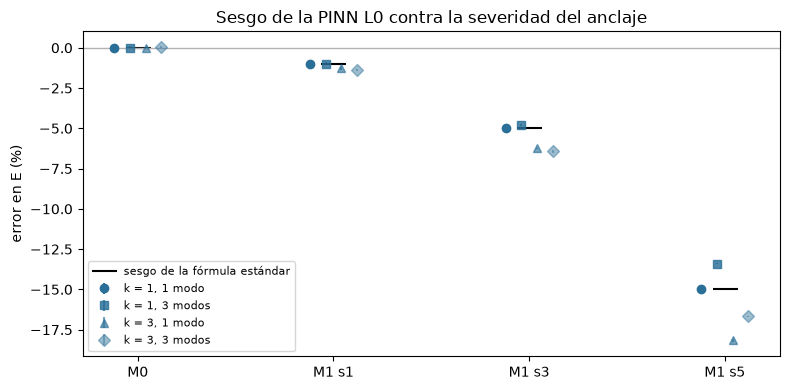

In [11]:
calibrado = {"m0": 0.0, "m1_s1": -1.0, "m1_s3": -5.0, "m1_s5": -15.0}
etiquetas = {"m0": "M0", "m1_s1": "M1 s1", "m1_s3": "M1 s3", "m1_s5": "M1 s5"}
x = np.arange(len(calibrado))

fig, ax = plt.subplots(figsize=(8, 4))
for i, ((k, modos), marcador) in enumerate(zip([(1, 1), (1, 3), (3, 1), (3, 3)], ["o", "s", "^", "D"])):
    g = tabla.xs((k, modos), level=("k", "modos")).reindex(list(calibrado))
    ax.errorbar(x + (i - 1.5) * 0.08, g["sesgo_E_pct"], yerr=g["dispersion_E_pct"], fmt=marcador, color=COLOR,
                alpha=1 - 0.18 * i, label=f"k = {k}, {modos} modo{'s' if modos > 1 else ''}")
ax.plot(x, list(calibrado.values()), "k_", ms=18, mew=1.5, label="sesgo de la fórmula estándar")
ax.axhline(0, color="0.7", lw=1)
ax.set(xticks=x, xticklabels=list(etiquetas.values()), ylabel="error en E (%)",
       title="Sesgo de la PINN L0 contra la severidad del anclaje")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Las barras de error (el IQR) existen pero son más pequeñas que los marcadores.

- **Con anclaje perfecto (M0)** el sesgo es de 0.02 % o menos y la dispersión menor a 0.1 %; sin ruido, el error máximo es 0.05 % en E y 0.7 % en σ₀. Las 220 corridas terminan sin falla.
- **Con anclaje que cede (M1)** el sesgo crece con la severidad. Con un voladizo y 1 modo coincide con el de la fórmula estándar (−1, −5 y −15 %): con la misma física supuesta, la PINN llega a la misma respuesta. Con 3 modos el sesgo baja un poco, porque la forma de los modos superiores aporta algo de información sobre el anclaje.
- **Con tres estructuras el sesgo en E es mayor** (hasta −18 %), porque el voladizo de 200 µm siente más el mismo anclaje, y σ₀ absorbe parte del error (hasta +23 %).
- **La dispersión es menor a 0.1 % en todas las celdas.** La PINN L0 es precisa pero sesgada: repetirla con otras semillas no revela el error. Por eso el sesgo y la dispersión se reportan por separado.

## 6. Conclusión

- **Algoritmo:** una PINN es apropiada para estimar un parámetro físico con pocos datos estructurados y física conocida. E se entrena como un número con significado físico, no se infiere de pesos opacos. La configuración (λ_PDE = 1 y 2000 iteraciones de L-BFGS) se fijó con experimentos.
- **Sub/sobreajuste:** dentro de la muestra no hay ni lo uno ni lo otro. El error de prueba es igual al de entrenamiento y está al nivel del ruido, y E no cambia con el número de puntos. Hay un sobreajuste leve de la forma con 5 puntos (χ² reducido de 0.72) que no afecta a E. El problema real es el **subajuste por error de modelo** cuando el anclaje cede: invisible en el ajuste, visible al predecir otras longitudes.
- **Como referencia:** la PINN L0 recupera E con un error de 0.02 % o menos cuando su física es correcta, y hereda el sesgo completo de la física ideal cuando no lo es. Ese sesgo, de −1 % a −18 % según la severidad, es lo que los modelos de las siguientes etapas (L1–L3) deben reducir.